# Analyze recorded route experiments

Reproduce the training curves, the comparison with always-on sensing, and the held-out transfer comparison from saved CSVs. The notebook displays the figures inline and writes PNGs to `runs/local/plots`. It does not train policies or depend on files outside this repository.

In [1]:
%matplotlib inline

from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import display

here = Path.cwd().resolve()
candidates = [root for parent in (here, *here.parents)
              for root in (parent, parent / "MORL4AVSO")]
REPO = next((root for root in candidates
             if (root / "experiments/short_route_curriculum.py").is_file()), None)
if REPO is None:
    raise FileNotFoundError("Open this notebook from the MORL4AVSO workspace.")

CURRICULUM = REPO / "runs/comparisons/short_route_varied_restart_20261122_125122_162138"
ALL_ON = REPO / "runs/training/time_completion_120s_1000ep_20261121_204241_241658"
EXPORTS = REPO / "runs/local/plots"
assert (CURRICULUM / "status.txt").read_text().strip() == "complete"
EXPORTS.mkdir(parents=True, exist_ok=True)

POLICIES = {"sarsa": "Expected SARSA", "dqn": "DQN", "dyna_dqn": "Dyna-DQN"}
ARMS = {"original": "Original traffic", "varied_restart": "Varied traffic + crash restarts"}
COLORS = {"original": "tab:blue", "varied_restart": "tab:orange"}
TRAINING_SEEDS = (42, 30042, 60042)
TRAINING_STEPS = 22_000

plt.style.use("default")
print("PNG exports:", EXPORTS.relative_to(REPO))


PNG exports: runs/local/plots


## Training progress on passing scenarios

This figure focuses on episodes in the varied-traffic arm that contained one or two slow vehicles. It excludes episodes generated by the original traffic generator and any episode cut off by the training budget. The horizontal axis includes all simulator decisions, including those in excluded episodes, so the budget remains 22,000 decisions per agent and seed.

Each point shows the mean passing-episode completion rate across three training seeds in a 2,000-decision window, based on when the episode ended. Shading spans the minimum and maximum per-seed rates. The first and last labels are training outcomes while exploration was changing. The transfer section compares learned policies on identical held-out tests.

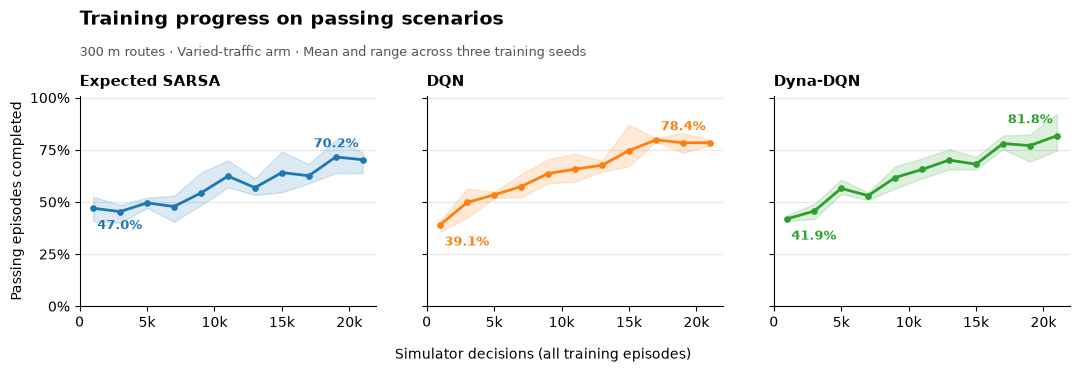

In [2]:
WINDOW = 2_000
windows = pd.RangeIndex(TRAINING_STEPS // WINDOW)
midpoints = (windows.to_numpy() + 0.5) * WINDOW
model_colors = {"sarsa": "tab:blue", "dqn": "tab:orange", "dyna_dqn": "tab:green"}

def passing_training_rates(policy):
    rates = {}
    for seed in TRAINING_SEEDS:
        path = CURRICULUM / "varied_restart" / f"seed_{seed}" / policy / "training.csv"
        log = pd.read_csv(path)
        assert log["steps"].sum() == TRAINING_STEPS
        passing = log.loc[~log["budget_cutoff"] & log["layout"].ne("original")].copy()
        passing["window"] = (passing["cumulative_steps"] - 1) // WINDOW
        rates[seed] = passing.groupby("window")["route_completed"].mean()
    rates = pd.DataFrame(rates).reindex(windows)
    assert rates.notna().all().all()
    return rates

fig, axes = plt.subplots(1, 3, figsize=(10.9, 3.9), sharex=True, sharey=True)
fig.subplots_adjust(left=0.075, right=0.984, bottom=0.19, top=0.73, wspace=0.17)
fig.text(0.075, 0.95, "Training progress on passing scenarios",
         fontsize=14, fontweight="bold", va="top")
fig.text(0.075, 0.86, "300 m routes · Varied-traffic arm · Mean and range across three training seeds",
         fontsize=9, color="0.33", va="top")

for ax, (policy, label) in zip(axes, POLICIES.items()):
    rates = passing_training_rates(policy)
    mean = rates.mean(axis=1)
    color = model_colors[policy]
    ax.fill_between(midpoints, rates.min(axis=1), rates.max(axis=1), color=color, alpha=0.16)
    ax.plot(midpoints, mean, marker="o", markersize=3.8, linewidth=2, color=color)
    for index, align, dx, dy in ((0, "left", 3, -15), (-1, "right", -3, 9)):
        ax.annotate(f"{mean.iloc[index]:.1%}", (midpoints[index], mean.iloc[index]),
                    xytext=(dx, dy), textcoords="offset points", ha=align,
                    fontsize=9.5, fontweight="bold", color=color)
    ax.set_title(label, loc="left", fontsize=10.5, fontweight="bold", pad=7)
    ax.set(xlim=(0, TRAINING_STEPS), ylim=(0, 1.01),
           xticks=[0, 5_000, 10_000, 15_000, 20_000],
           xticklabels=["0", "5k", "10k", "15k", "20k"],
           yticks=[0, 0.25, 0.5, 0.75, 1])
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Passing episodes completed")
fig.supxlabel("Simulator decisions (all training episodes)", y=0.047, fontsize=10)
fig.savefig(EXPORTS / "training_completion.png", dpi=300)
plt.show()


## Long-route baseline comparison

Each policy faced the same 12 matched trials on the 2,250 m route with a 120 s deadline: four traffic seeds in each of clear weather, rain, and fog. Mean finish time is calculated only for successful trips, so there is no bar for policies that finished none. Mean sensing power includes all 12 trials.

Adaptive Expected SARSA and learned all-on driving both finished 12/12. The adaptive policy used 27.5% less modeled sensing power.

,Policy,Finishes,Crashes,Mean finish time (s),Mean sensing power (W)
0,Adaptive Expected SARSA,12/12,0/12,110.0,89.19
1,Learned all-on,12/12,0/12,112.4,123.0
2,Fixed lane and speed,0/12,12/12,—,123.0
3,Random driving,0/12,12/12,—,123.0


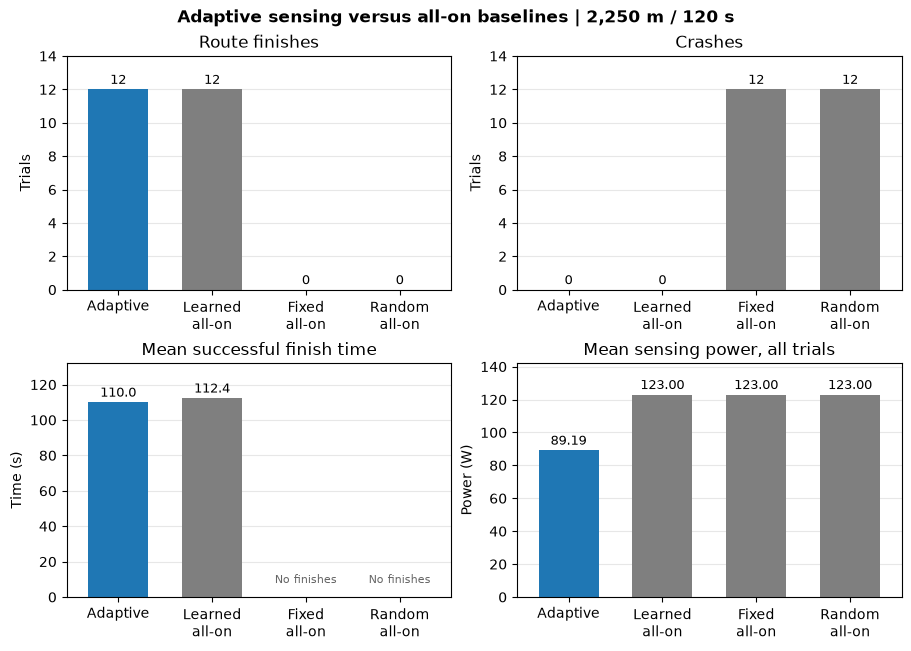

In [3]:
policy_order = ["adaptive", "learned_all_on", "idle_all_on", "random_all_on"]
labels = ["Adaptive", "Learned\nall-on", "Fixed\nall-on", "Random\nall-on"]
baseline_data = pd.read_csv(ALL_ON / "summary.csv").set_index("policy").loc[policy_order].copy()
n = baseline_data["episodes"].astype(int)
assert n.eq(12).all()
baseline_data["finishes"] = np.rint(baseline_data["completion_fraction"] * n).astype(int)
baseline_data["crashes"] = np.rint(baseline_data["crash_fraction"] * n).astype(int)

table = pd.DataFrame({
    "Policy": ["Adaptive Expected SARSA", "Learned all-on", "Fixed lane and speed", "Random driving"],
    "Finishes": [f"{k}/{total}" for k, total in zip(baseline_data["finishes"], n)],
    "Crashes": [f"{k}/{total}" for k, total in zip(baseline_data["crashes"], n)],
    "Mean finish time (s)": baseline_data["mean_completion_time_s"].round(1).to_numpy(),
    "Mean sensing power (W)": baseline_data["mean_power_w"].round(2).to_numpy(),
})
display(table.astype(object).fillna("—"))

metrics = [
    ("finishes", "Route finishes", "Trials", 14, 0),
    ("crashes", "Crashes", "Trials", 14, 0),
    ("mean_completion_time_s", "Mean successful finish time", "Time (s)", 132, 1),
    ("mean_power_w", "Mean sensing power, all trials", "Power (W)", 142, 2),
]
x = np.arange(len(policy_order))
colors = np.array(["tab:blue", "tab:gray", "tab:gray", "tab:gray"])
fig, axes = plt.subplots(2, 2, figsize=(9, 6.4), layout="constrained")
for ax, (field, title, units, upper, digits) in zip(axes.flat, metrics):
    values = baseline_data[field].to_numpy(dtype=float)
    valid = np.isfinite(values)
    ax.bar(x[valid], values[valid], color=colors[valid], width=0.64)
    for position, value in zip(x[valid], values[valid]):
        ax.annotate(f"{value:.{digits}f}", (position, value), xytext=(0, 4),
                    textcoords="offset points", ha="center", fontsize=9)
    for position in x[~valid]:
        ax.text(position, upper * 0.06, "No finishes", ha="center", fontsize=8, color="0.4")
    ax.set(title=title, ylabel=units, ylim=(0, upper), xlim=(-0.55, 3.55))
    ax.set_xticks(x, labels)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("Adaptive sensing versus all-on baselines | 2,250 m / 120 s", fontweight="bold")
fig.savefig(EXPORTS / "baseline_comparison.png", dpi=300)
plt.show()


## Long-route transfer

Each bar pools 54 held-out trials (18 per training seed). Open dots are individual seed completion rates. Parenthetical conditions in the legend describe the training traffic, while the subplot titles describe the held-out test traffic.

Varied short-route training improved completion for all three policies on unseen overtaking layouts. On the long route with original traffic, Expected SARSA matched its original-training completion count and both neural agents finished fewer trips.

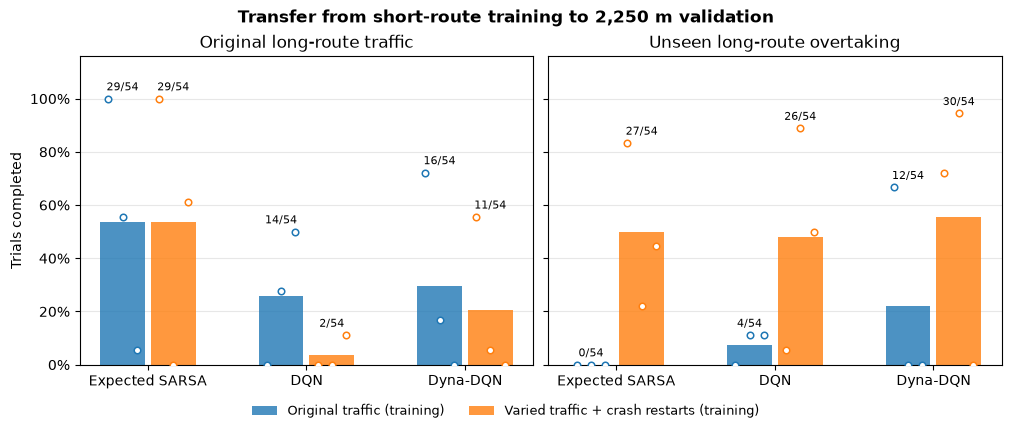

In [4]:
pooled = pd.read_csv(CURRICULUM / "summary.csv").set_index(["test_stage", "policy", "arm"])
per_seed = pd.read_csv(CURRICULUM / "summary_by_training_seed.csv").set_index(
    ["test_stage", "policy", "arm", "training_seed"]
)
stages = {"long_original": "Original long-route traffic",
          "long_overtaking_unseen": "Unseen long-route overtaking"}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True, layout="constrained")
x = np.arange(len(POLICIES))
bar_width = 0.32

for ax, (stage, title) in zip(axes, stages.items()):
    for idx, (arm, label) in enumerate(ARMS.items()):
        centers = x + (idx - 0.5) * bar_width
        for position, policy in zip(centers, POLICIES):
            row = pooled.loc[(stage, policy, arm)]
            trials, finishes = int(row["trials"]), int(row["finishes"])
            assert trials == 54
            fraction = finishes / trials
            ax.bar(position, fraction, width=bar_width * 0.88, color=COLORS[arm], alpha=0.8,
                   label=label if policy == "sarsa" else None)
            seeds = per_seed.loc[(stage, policy, arm), :].reindex(TRAINING_SEEDS)
            assert seeds["trials"].eq(18).all() and seeds["finishes"].sum() == finishes
            rates = seeds["finishes"] / seeds["trials"]
            jitter = np.linspace(-0.09, 0.09, len(rates))
            ax.scatter(position + jitter, rates, s=22, facecolor="white",
                       edgecolor=COLORS[arm], linewidth=1.1, zorder=3)
            ax.annotate(f"{finishes}/{trials}", (position, max(fraction, rates.max())),
                        xytext=(0, 6), textcoords="offset points", ha="center", fontsize=8)
    ax.set(title=title, ylim=(0, 1.16))
    ax.set_xticks(x, list(POLICIES.values()))
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.3)
    ax.yaxis.set_major_formatter(PercentFormatter(1))

axes[0].set_ylabel("Trials completed")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, [f"{label} (training)" for label in labels], loc="outside lower center",
           ncol=2, frameon=False, fontsize=9)
fig.suptitle("Transfer from short-route training to 2,250 m validation", fontweight="bold")
fig.savefig(EXPORTS / "long_route_transfer.png", dpi=300)
plt.show()
